In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Housing.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print("Null Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Null Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


In [3]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


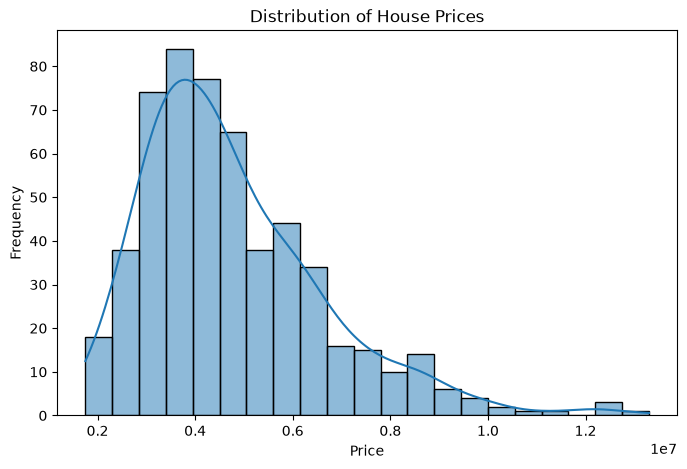

In [4]:
plt.figure(figsize=(8,5))
sns.histplot(df['price'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

### Observation
House prices are positively skewed, meaning most houses are concentrated in the lower to middle price range, while a smaller number of houses have very high prices.

## Feature Selection

The target variable is `price`.

The features selected as potential predictors are:

- `area` — larger houses are generally expected to have higher prices.
- `bedrooms` and `bathrooms` — more rooms can increase the value of a house.
- `stories` — the number of floors may affect house price.
- `parking` — parking availability can influence property value.
- `mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, and `prefarea` — these property features may influence buyer demand and price.
- `furnishingstatus` — furnished and semi-furnished houses may have different prices from unfurnished houses.

All relevant features will initially be retained, while categorical variables will be converted into numerical form using One-Hot Encoding before training the model.

## Missing Values and Categorical Encoding

The dataset was checked for missing values and none were found, so no imputation was required.

Categorical variables were converted into numerical variables using One-Hot Encoding so they can be used by the Linear Regression model.

In [5]:
# One-Hot Encoding categorical features
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

df_encoded.head()

Original shape: (545, 13)
Encoded shape: (545, 14)


,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,12250000,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,12250000,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,12215000,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,11410000,7420,4,1,2,2,1,1,1,0,1,0,0,0


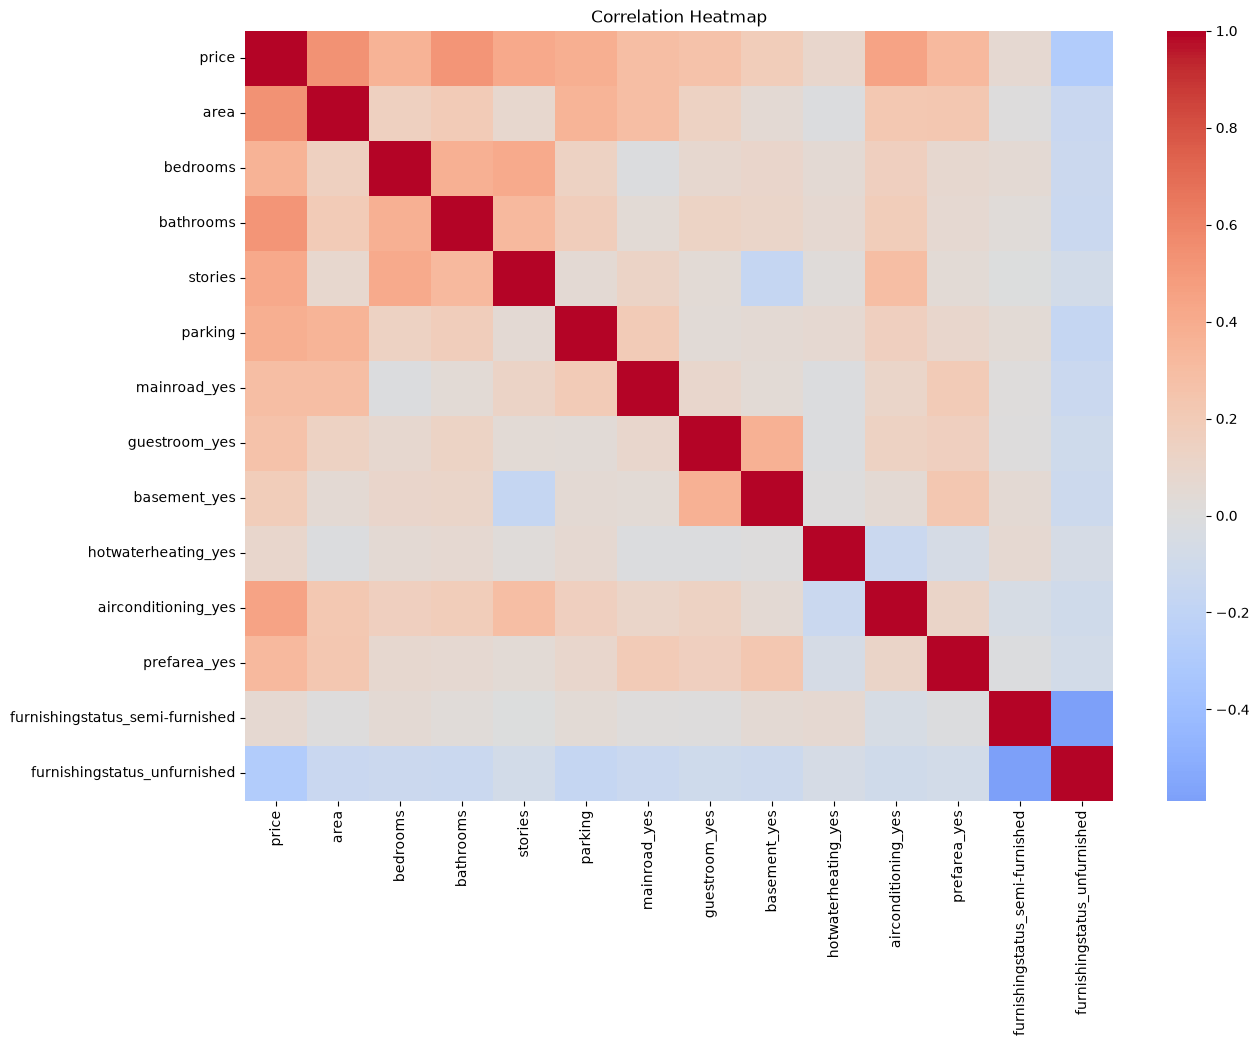

In [6]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df_encoded.corr(),
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.show()

In [7]:
price_correlation = (
    df_encoded.corr()['price']
    .sort_values(ascending=False)
)

price_correlation

price                              1.000000
area                               0.535997
bathrooms                          0.517545
airconditioning_yes                0.452954
stories                            0.420712
parking                            0.384394
bedrooms                           0.366494
prefarea_yes                       0.329777
mainroad_yes                       0.296898
guestroom_yes                      0.255517
basement_yes                       0.187057
hotwaterheating_yes                0.093073
furnishingstatus_semi-furnished    0.063656
furnishingstatus_unfurnished      -0.280587
Name: price, dtype: float64

### Correlation Observation

The features most positively correlated with house price are `area`, `bathrooms`, `airconditioning`, `stories`, and `parking`. This suggests that larger houses with more bathrooms, additional floors, parking spaces, and air conditioning tend to have higher prices.

`furnishingstatus_unfurnished` has a negative correlation with price, suggesting that unfurnished houses tend to have lower prices compared with furnished houses.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Features and target
X = df_encoded.drop('price', axis=1)
y = df_encoded['price']

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (436, 13)
Test set: (109, 13)


In [9]:
# Train Linear Regression model
model = LinearRegression()

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Model trained successfully.")

Model trained successfully.


In [10]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Squared Error (MSE): 1754318687330.6643
Root Mean Squared Error (RMSE): 1324506.9600914388
R² Score: 0.6529242642153184


## Model Evaluation

The Linear Regression model was evaluated using MSE, RMSE, and R².

- MSE measures the average squared prediction error.
- RMSE shows the typical prediction error in the same unit as house price.
- R² shows how much of the variation in house prices is explained by the model. A value closer to 1 indicates a better fit.

### Model Evaluation Observation

The Linear Regression model achieved an R² score of 0.653, meaning it explains about 65.3% of the variation in house prices.

The RMSE is approximately 1.32 million, which represents the typical prediction error of the model.

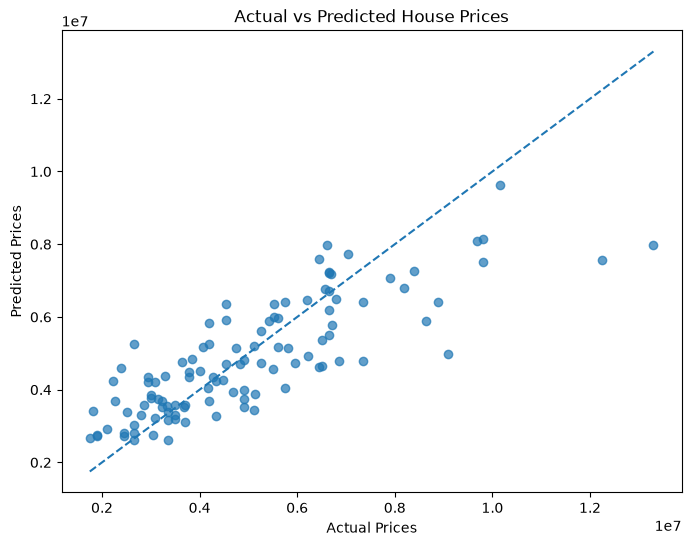

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual vs Predicted House Prices')

plt.show()

### Observation

The predicted prices generally follow the actual prices, although there are some noticeable deviations. Points closer to the diagonal line represent more accurate predictions.

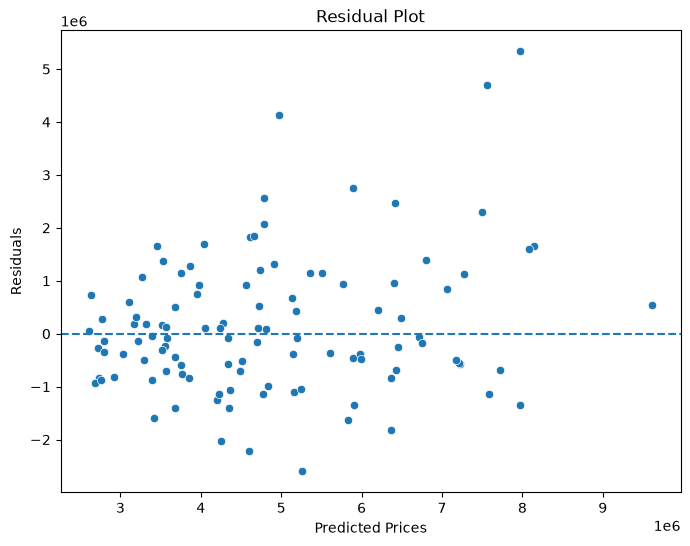

In [12]:
# Calculate residuals
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_pred, y=residuals)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

### Residual Plot Observation

The residuals are scattered around zero, although some larger errors are visible. Since there is no strong systematic pattern, the Linear Regression model provides a reasonable fit to the data.

In [13]:
# Coefficient Analysis

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

coefficients

,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05
7,basement_yes,3.902512e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
4,parking,2.248419e+05
1,bedrooms,7.677870e+04


In [14]:
print("Top Positive Coefficients:")
display(coefficients.head(5))

print("Top Negative Coefficients:")
display(coefficients.tail(5))

Top Positive Coefficients:


,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05


Top Negative Coefficients:


,Feature,Coefficient
4,parking,224841.913277
1,bedrooms,76778.701634
0,area,235.968805
11,furnishingstatus_semi-furnished,-126881.817585
12,furnishingstatus_unfurnished,-413645.062228


## Coefficient Analysis

Positive coefficients indicate features associated with higher predicted house prices, while negative coefficients indicate features associated with lower predicted prices.

The coefficient values show the expected change in predicted price when a feature increases by one unit, while the other features remain constant.

### Coefficient Analysis Observation

The strongest positive coefficient is `bathrooms`, suggesting that additional bathrooms have the largest positive association with predicted house price. Other strong positive factors include air conditioning, hot water heating, preferred area location, and number of stories.

The strongest negative coefficient is `furnishingstatus_unfurnished`, indicating that unfurnished houses are predicted to have lower prices compared with furnished houses. Semi-furnished houses also show a smaller negative effect.

In [15]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge MSE:", ridge_mse)
print("Ridge RMSE:", ridge_rmse)
print("Ridge R² Score:", ridge_r2)

Ridge MSE: 1756474279575.285
Ridge RMSE: 1325320.4441097574
Ridge R² Score: 0.6524978002155009


## Ridge Regression Comparison

The Ridge Regression model achieved an R² score of 0.6525 and an RMSE of approximately 1.33 million.

The original Linear Regression model achieved a slightly higher R² score of 0.6529 and a slightly lower RMSE of approximately 1.32 million. Therefore, Ridge Regression did not improve performance on this dataset, although the results are very similar.